# Kali ini kita akan belajar inspeksi data

Importing library

In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.model_selection import cross_validate, KFold
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

## Read Dataset

In [83]:
insurance_dataset = pd.read_csv("../../dataset/insurance.csv")
insurance_dataset.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Cek info dataset

In [84]:
insurance_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


## cek missing value dataset

In [85]:
insurance_dataset.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Outlier management

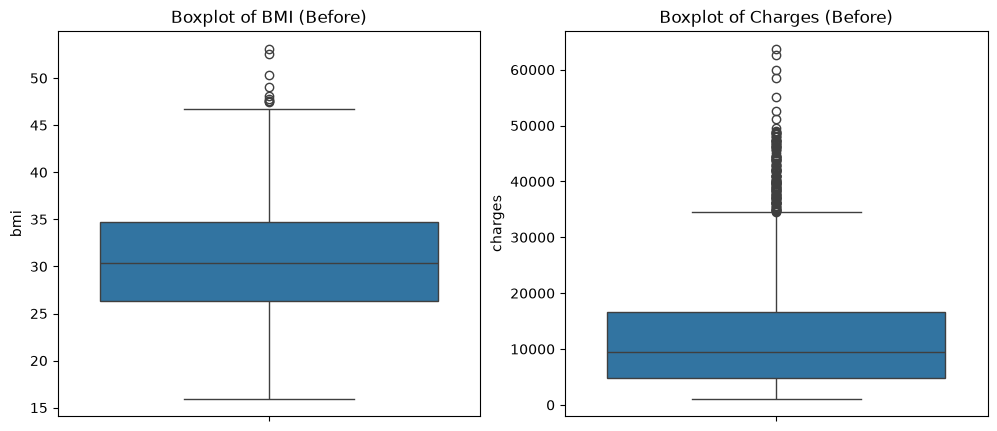

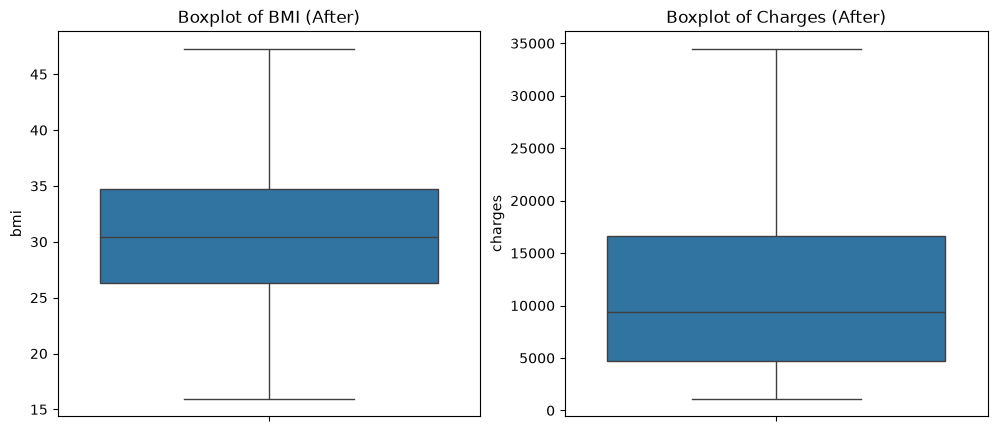

In [86]:
# Visualizing Outliers before handling
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y=insurance_dataset['bmi'])
plt.title('Boxplot of BMI (Before)')

plt.subplot(1, 2, 2)
sns.boxplot(y=insurance_dataset['charges'])
plt.title('Boxplot of Charges (Before)')
plt.show()

# Handling Outliers using IQR method (Capping)
def cap_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    data[column] = np.where(data[column] > upper_bound, upper_bound, data[column])
    data[column] = np.where(data[column] < lower_bound, lower_bound, data[column])
    return data

# Cap Outliers dari BMI dan Charges
df_cleaned = cap_outliers(insurance_dataset.copy(), 'bmi')
df_cleaned = cap_outliers(df_cleaned, 'charges')

# Validating after capping
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y=df_cleaned['bmi'])
plt.title('Boxplot of BMI (After)')

plt.subplot(1, 2, 2)
sns.boxplot(y=df_cleaned['charges'])
plt.title('Boxplot of Charges (After)')
plt.show()


Split data inden, depent

In [87]:
X = df_cleaned.drop(columns="charges")
y = df_cleaned['charges']

In [88]:
num_cols = ["age", "bmi", "children"]
cat_cols = ['sex', "smoker", "region"]

In [89]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first"), cat_cols)
])

In [90]:
alphas = np.logspace(-3, 3, 50)
models = {
    "Linear Regression": make_pipeline(preprocess, LinearRegression()),
    "Ridge" : make_pipeline(preprocess, RidgeCV(alphas=alphas)),
    "Lasso" : make_pipeline(preprocess, LassoCV(alphas=alphas, max_iter=10000)),
    "Gradient Boosting" : make_pipeline(preprocess, GradientBoostingRegressor(random_state=42))
 }

In [91]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

dibawah ini merupakan hasil dengan penangan outlier

In [92]:
hasil = []
for name, model in models.items():
    cv = cross_validate(model, X, y, cv=kf, scoring=scoring)
    hasil.append({
        "Model": name,
        "MAE" : -cv["test_MAE"].mean(),
        "RMSE" : -cv["test_RMSE"].mean(),
        "R2" : cv["test_R2"].mean(),
        "R2 std" : cv["test_R2"].std()
    })


pd.DataFrame(hasil).sort_values("RMSE").round(4)

,Model,MAE,RMSE,R2,R2 std
3,Gradient Boosting,2334.5056,4316.4494,0.8159,0.0330
0,Linear Regression,3358.2451,5120.4817,0.7409,0.0479
1,Ridge,3363.1313,5120.4997,0.7409,0.0478
2,Lasso,3362.0528,5122.6061,0.7407,0.0474
